In [1]:
import tensorflow as tf
import numpy as np
import math
import pandas as pd

2025-04-09 15:41:59.212919: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-09 15:41:59.213280: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-04-09 15:41:59.215538: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-04-09 15:41:59.222762: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-04-09 15:41:59.234196: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been 

### Formulas volume

In [2]:
sigma_calibro = 0.01
sigma_calibro_2 = 0.05

to vectorize a function:  

use convert_to_tensor, which allows arrays, not tf.constant  
in formulas, lik for swrt, use tf. not math.
rememeber .numpy() in some palces

In [3]:
def volume_sfera(d_array, sigma_calibro=sigma_calibro):
    """
    Calcola il volume e l'incertezza per un array di diametri.
    d_array: array-like (list, numpy array, pandas Series)
    Ritorna due numpy array: volume e incertezza
    """
    d_array = tf.convert_to_tensor(d_array, dtype=tf.float32)

    def V_sfera(d):
        return (4/3) * 3.1416 * (d / 2) ** 3

    with tf.GradientTape() as tape:
        tape.watch(d_array)
        v_array = V_sfera(d_array)

    dv_dd = tape.gradient(v_array, d_array)
    sigma_array = dv_dd.numpy() * sigma_calibro

    return v_array.numpy(), sigma_array


In [4]:
def volume_cilindro(d,h, sigma_d = sigma_calibro, sigma_h=sigma_calibro):
    '''Volume in funzione di diamtero e altezza'''

    def V_cilindro(d,h):
        return 3.14*((d/2)**2)*h

    d_cil = tf.convert_to_tensor(d, dtype=tf.float32)
    h_cil = tf.convert_to_tensor(h, dtype=tf.float32)

    with tf.GradientTape(persistent=True) as tape:
        tape.watch([d_cil,h_cil])
        v_cil = V_cilindro(d_cil,h_cil)

    df_dd_cil = tape.gradient(v_cil, d_cil)
    df_dh_cil = tape.gradient(v_cil, h_cil)

    sigma_cil = tf.sqrt((df_dd_cil.numpy() * sigma_d)**2 + (df_dh_cil.numpy() * sigma_h)**2)

    return v_cil.numpy(), sigma_cil

In [5]:
def volume_esagono(d,h):
    '''Volume in funzione di diamtero e altezza'''
    
    def V_esagono(d,h):
        return 1/2 * 6*(d/math.sqrt(3)) * (d/2) *h
        # V = 1/2 *p *a * h

    d = tf.convert_to_tensor(d, dtype=tf.float32)
    h = tf.convert_to_tensor(h, dtype=tf.float32)

    with tf.GradientTape(persistent=True) as tape:
        tape.watch([d,h])
        v_esa = V_esagono(d,h)

    df_dd = tape.gradient(v_esa, d)
    df_dh = tape.gradient(v_esa, h)

    sigma_esa = tf.sqrt((df_dd.numpy() * sigma_calibro)**2 + (df_dh.numpy() * sigma_calibro)**2)

    return v_esa.numpy(), sigma_esa

In [6]:
def volume_parallelepipedo(a,b,c, sigma_a = sigma_calibro, sigma_b=sigma_calibro, sigma_c=sigma_calibro):
    '''Volume in funzione dei tre lati'''

    def V_parallelepipedo(a,b,c):
        return a*b*c

    a = tf.convert_to_tensor(a, dtype=tf.float32)
    b = tf.convert_to_tensor(b, dtype=tf.float32)
    c = tf.convert_to_tensor(c, dtype=tf.float32)


    with tf.GradientTape(persistent=True) as tape:
        tape.watch([a,b,c])
        v_para = V_parallelepipedo(a,b,c)

    df_da = tape.gradient(v_para, a)
    df_db = tape.gradient(v_para, b)
    df_dc = tape.gradient(v_para, c)

    sigma_para = tf.sqrt((df_da.numpy() * sigma_a)**2 + (df_db * sigma_b)**2 + (df_dc * sigma_c)**2)

    return v_para.numpy(), sigma_para

### Get data

cyl has diameter, height  

para has sides a,b,c

each col is an object

#### Acciaio

In [7]:
data_acciaio = {'radius' : [9.52, 12.69, 18.25, 18.26, 22.23]}
df_acciaio = pd.DataFrame(data_acciaio)

#### Alluminium

In [8]:
alluminium_cyl = {'diameter': [6.47, 12.45, 19.79],
                  'height' : [19.34, 19.04, 19.20]}

alluminium_para = {'a':[10.14, 8.13],
                   'b':[10.14, 20.08],
                   'c': [17.62, 17.52]}

#### Ottone

In [9]:
ottone_cyl = {'diameter': [10.46, 6.47],
                  'height' : [16.47, 119.8]}

ottone_para = {'a':[5.18, 10.47],
                'b':[5.18, 10.47],
                'c': [22.85, 42.3]}

ottone_hex = {'diameter': [15.44],
              'height' : [17.82]}

## Compute volumes

### Alluminio

In [10]:
v_cyl, sigma_cyl = volume_cilindro(alluminium_cyl['diameter'], alluminium_cyl['height'])
v_para, sigma_para = volume_parallelepipedo(alluminium_para['a'], alluminium_para['b'], alluminium_para['c'])

df_alluminium = pd.concat([
    pd.DataFrame({'vol': v_cyl, 'sigma_vol': sigma_cyl}),
    pd.DataFrame({'vol': v_para, 'sigma_vol': sigma_para})
], ignore_index=True)


In [11]:
df_alluminium

,vol,sigma_vol
0,635.527954,1.991832
1,2316.729736,3.915512
2,5902.860352,6.711121
3,1811.681641,2.727921
4,2860.146973,4.131628


### Ottone

In [12]:
v_cyl, sigma_cyl = volume_cilindro(ottone_cyl['diameter'], ottone_cyl['height'])
v_para, sigma_para = volume_parallelepipedo(ottone_para['a'], ottone_para['b'], ottone_para['c'])
v_hex, sigma_hex = volume_esagono(ottone_hex['diameter'], ottone_hex['height'])

df_ottone = pd.concat([
    pd.DataFrame({'vol': v_cyl, 'sigma_vol': sigma_cyl}),
    pd.DataFrame({'vol': v_para, 'sigma_vol': sigma_para}),
    pd.DataFrame({'vol': v_hex, 'sigma_vol': sigma_hex})
], ignore_index=True)

In [13]:
df_ottone

,vol,sigma_vol
0,1414.577026,2.837829
1,3936.724609,12.173600
2,613.120300,1.695275
3,4636.964355,6.358490
4,3679.026611,5.193563


### Acciaio

In [14]:
df_acciaio["vol"], df_acciaio["sigma_vol"] = volume_sfera(df_acciaio["radius"])

In [15]:
df_acciaio

,radius,vol,sigma_vol
0,9.52,451.762848,1.423622
1,12.69,1070.001587,2.529555
2,18.25,3182.645264,5.231746
3,18.26,3187.879883,5.237480
4,22.23,5751.988281,7.762467


## Compute density

mass in is grams [g]  
volume is in [cm^2]
density is in [kg/m^3]

### Get data: masses

order is like before: cyl, para, hex

In [16]:
df_alluminium['mass'] = [1.455, 5.764, 16.025, 4.863, 7.658]
df_ottone['mass'] = [10.486, 29.524, 4.761, 34.837, 28.972]
df_acciaio['mass'] = [3.352, 8.359, 24.816, 24.820, 44.827]

In [17]:
def densita(m,v,sigma_v,sigma_m=0.001):
    
    def density(m,v):
        return m/v

    m = tf.convert_to_tensor(m, dtype=tf.float32)
    v = tf.convert_to_tensor(v, dtype=tf.float32)
    sigma_v = tf.convert_to_tensor(sigma_v, dtype=tf.float32)

    with tf.GradientTape(persistent=True) as tape:
        tape.watch([m, v])  # Ensure x and y are being watched
        d = density(m, v) *1000000

    df_dm = tape.gradient(d,m)
    df_dv = tape.gradient(d,v)
    sigma_d = tf.sqrt((df_dm.numpy() *sigma_m)**2 + (df_dv.numpy() * sigma_v.numpy())**2)
    
    return d,sigma_d

In [18]:
df_acciaio['density'],  df_acciaio['sigma_density'] = densita(df_acciaio.mass, df_acciaio.vol, df_acciaio.sigma_vol)
df_ottone['density'],  df_ottone['sigma_density'] = densita(df_ottone.mass, df_ottone.vol, df_ottone.sigma_vol)
df_alluminium['density'],  df_alluminium['sigma_density'] = densita(df_alluminium.mass, df_alluminium.vol, df_alluminium.sigma_vol)

In [19]:
df_alluminium

,vol,sigma_vol,mass,density,sigma_density
0,635.527954,1.991832,1.455,2289.435059,7.345903
1,2316.729736,3.915512,5.764,2487.989746,4.227056
2,5902.860352,6.711121,16.025,2714.785400,3.091159
3,1811.681641,2.727921,4.863,2684.246338,4.079293
4,2860.146973,4.131628,7.658,2677.484863,3.883534


to add a col need to call it with ['name'], can't call it with .name

### Plot

In [20]:
x1 = df_acciaio['vol'].to_numpy()
y1 = df_acciaio['mass'].to_numpy()

x2 = df_ottone['vol'].to_numpy()
y2 = df_ottone['mass'].to_numpy()

x3 = df_alluminium['vol'].to_numpy()
y3 = df_alluminium['mass'].to_numpy()

0.007813053502456313 1.8351341333605428e-05 -0.08589459440224156 0.060712814563754346
0.007586846934802716 0.00019757596648261499 0.04733862190231275 0.642722880774437
0.002766244228701864 5.473184597731858e-05 -0.33076762930913817 0.17663642078505312


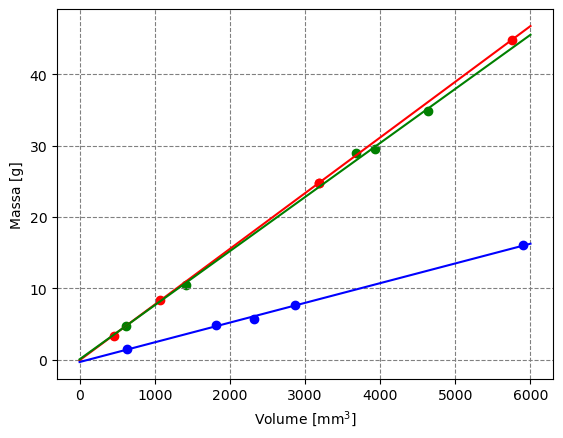

In [21]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit


plt.figure('Grafico massa-volume')

plt.scatter(x1,y1, c='red', label='acciaio')
plt.scatter(x2,y2, c='green', label='alluminio')
plt.scatter(x3,y3, c='blue', label='ottone')


def line(x, m, q):
    """Modello lineare di fit."""
    return m * x + q

x = np.linspace(0., 6000., 100)



popt, pcov = curve_fit(line, x1,y1)
m_hat, q_hat = popt
sigma_m, sigma_q = np.sqrt(pcov.diagonal())
print(m_hat, sigma_m, q_hat, sigma_q)
plt.plot(x, line(x, m_hat, q_hat), c='red')

popt, pcov = curve_fit(line, x2,y2)
m_hat, q_hat = popt
sigma_m, sigma_q = np.sqrt(pcov.diagonal())
print(m_hat, sigma_m, q_hat, sigma_q)
plt.plot(x, line(x, m_hat, q_hat), c='green')

popt, pcov = curve_fit(line, x3,y3)
m_hat, q_hat = popt
sigma_m, sigma_q = np.sqrt(pcov.diagonal())
print(m_hat, sigma_m, q_hat, sigma_q)
plt.plot(x, line(x, m_hat, q_hat), c='blue')



plt.xlabel('Volume [mm$^3$]')
plt.ylabel('Massa [g]')
plt.grid(which='both', ls='dashed', color='gray')
plt.show()

### Grafico logaritmico

2 methods to make logarithm graph:  

plug normal points, but with log axes  
plug ln(x) points in NORMAL axes  
in both cases, if hve power law, should get a line  
cannot do both ln(x) points and log axes, don't work  

use power law as function, thenn use both x and y log axes

logarithm graphs, method 1:  
plot real points (not ln points) on log axes  

power law: both x and y axis have log scale  
exponential law: only y axis has log scale  

In [22]:
def power_law(x, norm, index):
    """Modello di tipo legge di potenza"""
    return norm * (x**index)

In [23]:
d = df_acciaio.radius
r = d / 2.0
sigma_r = sigma_calibro / 2.0

0.032067300382210215 0.0009633492899123922 3.0075971482227146 0.012926556638516435


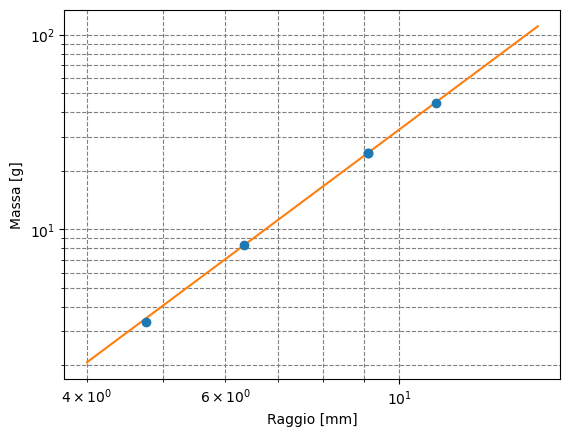

In [24]:
plt.figure('Grafico massa-raggio')

plt.errorbar(r, df_acciaio.mass, sigma_m, sigma_r, fmt='o')

popt, pcov = curve_fit(power_law, r, df_acciaio.mass)
norm_hat, index_hat = popt
sigma_norm, sigma_index = np.sqrt(pcov.diagonal())
print(norm_hat, sigma_norm, index_hat, sigma_index)

x = np.linspace(4., 15., 100)
plt.plot(x, power_law(x, norm_hat, index_hat))

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Raggio [mm]')
plt.ylabel('Massa [g]')
plt.grid(which='both', ls='dashed', color='gray')

plt.show()
